# CS-781 Capstone — Phase 2: Legal NER (L-NER) with the Phase-1 **Mamba** (selective state-space) model

The Phase-1 Mamba LM (20 blocks, d=512, d_state=32, d_conv=16, expand=3, about 86M params) is adapted to predict `[start_char, end_char, label]`
spans for the 12 legal entity types. The metric is strict Macro-F1.

### What was wrong in the GQLA Phase-2 fine-tuning, and what this notebook does instead
| # | GQLA Phase-2 notebook | Effect seen in its logs | Here |
|---|---|---|---|
| 1 | Causal backbone, and each word's tag read from its **first** sub-token, which has not even seen the rest of its own word | entity boundaries and types are guessed without any right context | **Bidirectional readout.** The default head is a BiGRU over the Mamba states. `head="bidir"` instead runs the *same* Phase-1 Mamba a second time over the reversed window. Every sub-token is labelled with its word's tag, and a word's prediction averages all its sub-tokens |
| 2 | "LORMA" was a gated LoRA, with B ≠ 0 at init | the worst technique (0.14), not even the Phase-1 model at step 0 | **LoRMA⁺ from the paper**: `W = (I + α/r·BA)·W₀` with `B = 0`, so it is exactly Phase 1 at init (self-tested) |
| 3 | KD student was a **randomly initialised** small model | 0.03 F1, and it breaks "start every experiment from Phase 1" | Student = **10 of the 20 Phase-1 blocks** (layer-dropping init, blocks 0,2,…,18), trained on the teacher's soft labels plus normalised hidden states |
| 4 | No LR schedule, one LR for body and head, 4 epochs | every run was still improving at the last epoch; full FT at 2e-5 lost to partial FT at 2e-4 | warm-up + linear decay, head LR × 10, up to 10 epochs with early stopping on dev F1, and a per-method LR |
| 5 | Dev scored against *BIO-reconstructed* spans; non-overlapping 512-token chunks | offset errors hidden; entities cut at chunk edges | scored against the **real gold spans**, with an alignment ceiling printed; **overlapping windows** whose overlaps are merged with centre weighting |
| 6 | The submission cell always rebuilt a *partial-FT* model, whatever `BEST_EXP_NAME` was; the run was on CPU | wrong architecture for other experiments | an experiment **registry** rebuilds the right model for every zip, and the notebook stops if there is no GPU |

### Experiments (brief §8.2: ≥ 5 different techniques + KD, LoRMA compulsory)
| # | name | technique | trained |
|---|---|---|---|
| 1 | `exp1_full_ft` | Full fine-tuning (also the KD teacher) | everything |
| 2 | `exp2_partial_ft` | Partial / layer-wise FT | top 10 of 20 blocks + final norm |
| 3 | `exp3_lora` | LoRA r=16 | `in_proj`, `out_proj` of every block |
| 4 | `exp4_lorma` | **LoRMA⁺ r=16 (compulsory)** | same matrices, multiplicative update |
| 5 | `exp5_adapters` | Houlsby bottleneck adapters | one adapter after every mixer |
| 6 | `exp6_kd` | **Knowledge distillation (mandatory)** | 10-block student from Phase-1 blocks |
| extra | `x_bitfit`, `x_ssm_only`, `x_linear_head`, `x_bidir` | BitFit · Mamba-specific Δ/A/D tuning · causal-only ablation · reversed-pass head | |

The task head and the final norm are trainable in every PEFT method. All hyper-parameters are **starting points**, not tuned values (course rules §17.5).

## 0. Setup

In [ ]:
!pip -q install huggingface_hub

In [ ]:
import os, re, json, math, time, random, zipfile, gc, copy, unicodedata
from collections import defaultdict, Counter
from functools import partial

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.utils.checkpoint import checkpoint as grad_checkpoint

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
if DEVICE.type != "cuda":
    raise RuntimeError("No GPU: Runtime -> Change runtime type -> T4 GPU (the GQLA Phase-2 run went to CPU by accident).")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    IN_COLAB = False

Device: cuda | Tesla T4
Mounted at /content/drive


## 1. Config
Paths and model hyper-parameters are those of your Mamba Phase-1 notebook (`cache_dir`, `mamba_checkpoints/mamba_large.pt`, which is the checkpoint
your Phase-1 predictions were made with). The architecture **must** match, because the checkpoint is loaded strictly.

In [ ]:
cache_dir      = "/content/drive/MyDrive/CS781/Capstone-Project/legal_dataset_cache"
TOKENIZER_PATH = os.path.join(cache_dir, "final_bpe_en.json")
P1_CKPT_PATH   = os.path.join(cache_dir, "mamba_checkpoints", "mamba_large.pt")      # or best_model.pt if you prefer it
MAMBA_CFG = dict(d_model=512, n_layers=20, d_state=32, d_conv=16, expand=3, dropout=0.1)   # = Phase-1 notebook

PHASE2_DIR    = "/content/drive/MyDrive/CS781/Capstone-Project/phase2_lner_mamba"
CKPT_DIR      = os.path.join(PHASE2_DIR, "checkpoints")
SUB_DIR       = os.path.join(PHASE2_DIR, "submissions")
RESULTS_PATH  = os.path.join(PHASE2_DIR, "results.json")
for d in (PHASE2_DIR, CKPT_DIR, SUB_DIR):
    os.makedirs(d, exist_ok=True)
for what, p in (("tokenizer", TOKENIZER_PATH), ("checkpoint", P1_CKPT_PATH)):
    if not os.path.isfile(p):
        raise FileNotFoundError(f"Phase-1 {what} file not found (or it is a folder): {p}")

LOCAL_DATA_DIR = None     # e.g. "/content/Phase_2_LNER"; None -> HF download
HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        pass

# ---- data / windows ----
DEV_STRATEGY   = "fold2"  # "fold2": train=fold1, dev=fold2 | "holdout": pool both folds, hold out DEV_FRAC of the docs
DEV_FRAC       = 0.15
MAX_LEN        = 512      # window in BPE tokens (the Phase-1 training length)
STRIDE         = 384      # MAX_LEN - STRIDE tokens of overlap between windows
APPEND_EOS     = False    # Phase-1 Mamba chunks were plain 512-token slices of documents (no per-chunk specials)
SUBTOKEN_LABEL = "word"   # every sub-token gets its word's tag ...
WORD_READOUT   = "mean"   # ... and a word's probabilities = mean over its sub-tokens ("first" = the GQLA behaviour, "last")

# ---- head ----
HEAD           = "bigru"  # "bigru" (forward Mamba + BiGRU) | "bidir" (forward + reversed Mamba pass) | "linear" (causal only)
RNN_HIDDEN     = 256

# ---- training ----
BATCH_SIZE     = 4        # the scan materialises (B, L, d_inner, d_state) per block: 4 x 512 fits a T4 with checkpointing
EVAL_BS        = 4
GRAD_ACCUM     = 2
EPOCHS         = 10
PATIENCE       = 3        # early stopping on dev strict Macro-F1
WARMUP_FRAC    = 0.06
WEIGHT_DECAY   = 0.01
FT_DROPOUT     = 0.1
HEAD_LR_MULT   = 10.0
USE_AMP        = True     # fp16 autocast on the projections; the selective scan always runs in fp32 (Phase-1 code)
GRAD_CKPT      = True
CLASS_WEIGHTING = None    # None | "sqrt_inv" (class-imbalance ablation)
O_WEIGHT       = 1.0
DECODE         = "viterbi"  # "viterbi" (BIO-constrained) | "argmax"
LOG_EVERY      = 50

## 2. Phase-1 BPE tokenizer (inference part, identical to Phase 1) + per-word normalisation (offsets stay in the raw text)

In [ ]:
import heapq

WORD_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)   # MUST match Phase 1

class BPETokenizer:
    _HEAP_THRESHOLD = 24
    _CACHE_LIMIT = 500_000

    def __init__(self, vocab_size, end_marker="</w>", reserved_tokens=None):
        self.vocab_size = vocab_size
        self.end_marker = end_marker
        self.reserved_tokens = reserved_tokens or ["<pad>", "<unk>", "<s>", "</s>"]
        self.itos = list(self.reserved_tokens)
        self.stoi = {t: i for i, t in enumerate(self.reserved_tokens)}
        self.merges = {}
        self._ready = False
        self._cache = {}

    @staticmethod
    def from_json(path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = BPETokenizer(data["vocab_size"], data.get("end_marker", "</w>"),
                           data.get("reserved_tokens", ["<pad>", "<unk>", "<s>", "</s>"]))
        tok.itos = data["itos"]; tok.stoi = data["stoi"]
        tok.merges = {tuple(p): r for p, r in data["merges"]}
        return tok

    def _prepare_inference(self):
        if self._ready:
            return
        self._byte_ids = [self.stoi[bytes([b]).decode("latin-1")] for b in range(256)]
        self._first_merge_id = len(self.itos) - len(self.merges)
        self._end_id = self.stoi.get(self.end_marker, self.stoi["<unk>"])
        base = self._first_merge_id
        for (a, b), r in self.merges.items():
            if self.itos[base + r] != self.itos[a] + self.itos[b]:
                raise ValueError("Merge/vocab mismatch: cannot infer merge ids from ranks.")
        self._M = len(self.itos)
        self._ranks = {a * self._M + b: r for (a, b), r in self.merges.items()}
        self._cache = {}
        self._ready = True

    def _merge_small(self, ids):
        get, M, base = self._ranks.get, self._M, self._first_merge_id
        while len(ids) > 1:
            best, best_i = None, -1
            for i in range(len(ids) - 1):
                r = get(ids[i] * M + ids[i + 1])
                if r is not None and (best is None or r < best):
                    best, best_i = r, i
            if best is None:
                break
            a, b, new = ids[best_i], ids[best_i + 1], base + best
            out, i, n = [], 0, len(ids)
            while i < n:
                if i < n - 1 and ids[i] == a and ids[i + 1] == b:
                    out.append(new); i += 2
                else:
                    out.append(ids[i]); i += 1
            ids = out
        return ids

    def _merge_heap(self, ids):
        get, M, base = self._ranks.get, self._M, self._first_merge_id
        n = len(ids)
        nxt = list(range(1, n + 1)); nxt[-1] = -1
        prv = list(range(-1, n - 1))
        alive = [True] * n
        heap = [(r, i) for i in range(n - 1) if (r := get(ids[i] * M + ids[i + 1])) is not None]
        heapq.heapify(heap)
        while heap:
            r, i = heapq.heappop(heap)
            if not alive[i]:
                continue
            j = nxt[i]
            if j == -1 or get(ids[i] * M + ids[j]) != r:
                continue
            ids[i] = base + r
            alive[j] = False
            k = nxt[j]; nxt[i] = k
            if k != -1:
                prv[k] = i
            p = prv[i]
            if p != -1 and (r2 := get(ids[p] * M + ids[i])) is not None:
                heapq.heappush(heap, (r2, p))
            if k != -1 and (r2 := get(ids[i] * M + ids[k])) is not None:
                heapq.heappush(heap, (r2, i))
        return [ids[i] for i in range(n) if alive[i]]

    def _bpe_word(self, word):
        self._prepare_inference()
        hit = self._cache.get(word)
        if hit is not None:
            return hit
        ids = [self._byte_ids[b] for b in word.encode("utf-8")] + [self._end_id]
        ids = self._merge_small(ids) if len(ids) <= self._HEAP_THRESHOLD else self._merge_heap(ids)
        result = tuple(ids)
        if len(self._cache) < self._CACHE_LIMIT:
            self._cache[word] = result
        return result

    def encode(self, text, add_special_tokens=True):
        self._prepare_inference()
        out = [self.stoi["<s>"]] if add_special_tokens else []
        for w in WORD_RE.findall(text):
            out.extend(self._bpe_word(w))
        if add_special_tokens:
            out.append(self.stoi["</s>"])
        return out


# Same character map as Phase-1 normalize_text(); applied per word (offsets stay in raw text)
_CHAR_MAP = {ord(c): None for c in ("​‌‍‎‏⁠﻿­�"
                                    "‪‫‬‭‮")}
_CHAR_MAP.update({ord(c): "'" for c in "‘’‚‛′ʼ"})
_CHAR_MAP.update({ord(c): '"' for c in "“”„‟″"})
_CHAR_MAP.update({ord(c): "-" for c in "‐‑‒–—―−"})

def normalize_word(w):
    w2 = w.translate(_CHAR_MAP)
    if not w2.isascii():
        w2 = unicodedata.normalize("NFKC", w2)
    w2 = "".join(w2.split())           # NFKC can create spaces (rare)
    return w2 if w2 else w             # never drop a word: keep it so it gets tokens


tokenizer = BPETokenizer.from_json(TOKENIZER_PATH)
tokenizer._prepare_inference()
PAD_ID, BOS_ID, EOS_ID = tokenizer.stoi["<pad>"], tokenizer.stoi["<s>"], tokenizer.stoi["</s>"]
VOCAB_SIZE = len(tokenizer.itos)
print(f"Tokenizer: vocab={VOCAB_SIZE:,} | PAD={PAD_ID} BOS={BOS_ID} EOS={EOS_ID}")

Tokenizer: vocab=32,768 | PAD=0 BOS=2 EOS=3


## 3. Phase-1 Mamba (copied unchanged from your Phase-1 notebook so the checkpoint loads strictly)
The forward-pass code is identical, including the fp32 chunked selective scan. Only the parts needed for training are kept; the decoding `step()` / `generate()` are dropped.

In [ ]:
USE_FAST_KERNEL, HAS_FAST_KERNEL = False, False
_MIN_LOG_DECAY = -8.0


def selective_scan_ref(x, dt, A, Bm, Cm, D):
    Bsz, L, Din = x.shape
    N = A.shape[1]
    h = x.new_zeros(Bsz, Din, N)
    ys = []
    for t in range(L):
        dA = torch.exp((dt[:, t, :, None] * A).clamp(min=_MIN_LOG_DECAY))
        dBx = (dt[:, t] * x[:, t])[:, :, None] * Bm[:, t, None, :]
        h = dA * h + dBx
        ys.append((h * Cm[:, t, None, :]).sum(-1))
    return torch.stack(ys, dim=1) + x * D, h


def selective_scan_chunked(x, dt, A, Bm, Cm, D, chunk=8):
    Bsz, L, Din = x.shape
    N = A.shape[1]
    pad = (-L) % chunk
    if pad:
        x, dt = F.pad(x, (0, 0, 0, pad)), F.pad(dt, (0, 0, 0, pad))
        Bm, Cm = F.pad(Bm, (0, 0, 0, pad)), F.pad(Cm, (0, 0, 0, pad))
    Lp = L + pad
    nc = Lp // chunk
    dA = (dt.unsqueeze(-1) * A).clamp(min=_MIN_LOG_DECAY)
    dBx = (dt * x).unsqueeze(-1) * Bm.unsqueeze(2)
    dA = dA.view(Bsz, nc, chunk, Din, N)
    dBx = dBx.view(Bsz, nc, chunk, Din, N)
    La = torch.cumsum(dA, dim=2)
    local = torch.exp(La) * torch.cumsum(dBx * torch.exp(-La), dim=2)
    chunk_decay = torch.exp(La[:, :, -1])
    chunk_end = local[:, :, -1]
    carry = x.new_zeros(Bsz, Din, N)
    prev = []
    for k in range(nc):
        prev.append(carry)
        carry = chunk_decay[:, k] * carry + chunk_end[:, k]
    prev = torch.stack(prev, dim=1)
    h = local + torch.exp(La) * prev.unsqueeze(2)
    y = (h * Cm.view(Bsz, nc, chunk, 1, N)).sum(-1).reshape(Bsz, Lp, Din)[:, :L]
    return y + x[:, :L] * D, carry


class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return xf.to(x.dtype) * self.weight


class MambaMixer(nn.Module):
    def __init__(self, d_model, d_state=16, d_conv=4, expand=2, dt_rank=None, dt_min=1e-3, dt_max=1e-1,
                 dt_init_floor=1e-4, scan_chunk=8):
        super().__init__()
        self.d_model, self.d_state, self.d_conv = d_model, d_state, d_conv
        self.d_inner = expand * d_model
        self.dt_rank = math.ceil(d_model / 16) if dt_rank is None else dt_rank
        self.scan_chunk = scan_chunk
        self.in_proj = nn.Linear(d_model, 2 * self.d_inner, bias=False)
        self.conv1d = nn.Conv1d(self.d_inner, self.d_inner, kernel_size=d_conv, groups=self.d_inner,
                                padding=d_conv - 1, bias=True)
        self.x_proj = nn.Linear(self.d_inner, self.dt_rank + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True)
        A = torch.arange(1, d_state + 1, dtype=torch.float32).repeat(self.d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)

    def forward(self, u):
        Bsz, L, _ = u.shape
        x, z = self.in_proj(u).chunk(2, dim=-1)
        x = self.conv1d(x.transpose(1, 2))[..., :L]                    # causal depthwise conv
        x = F.silu(x).transpose(1, 2)
        dt, Bm, Cm = torch.split(self.x_proj(x), [self.dt_rank, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(dt))
        A = -torch.exp(self.A_log.float())
        with torch.autocast(device_type=u.device.type, enabled=False):  # scan always in fp32
            y, _ = selective_scan_chunked(x.float(), dt.float(), A, Bm.float(), Cm.float(), self.D.float(),
                                          chunk=self.scan_chunk)
        y = y.to(z.dtype) * F.silu(z)
        return self.out_proj(y)


class MambaBlock(nn.Module):
    def __init__(self, d_model, dropout=0.1, **mixer_kwargs):
        super().__init__()
        self.norm = RMSNorm(d_model)
        self.mixer = MambaMixer(d_model, **mixer_kwargs)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return x + self.dropout(self.mixer(self.norm(x)))


class MambaLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, d_state=16, d_conv=4, expand=2, dropout=0.1, pad_token_id=0,
                 scan_chunk=8, grad_checkpointing=True):
        super().__init__()
        self.vocab_size, self.pad_token_id = vocab_size, pad_token_id
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_token_id)
        self.layers = nn.ModuleList([MambaBlock(d_model, dropout=dropout, d_state=d_state, d_conv=d_conv,
                                                expand=expand, scan_chunk=scan_chunk) for _ in range(n_layers)])
        self.norm_final = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)


_P1 = {}

def load_phase1_mamba(dropout=FT_DROPOUT):
    """fresh MambaLM with the Phase-1 weights (state dict cached on CPU so every experiment starts identically)"""
    if "sd" not in _P1:
        ck = torch.load(P1_CKPT_PATH, map_location="cpu", weights_only=False)
        sd = ck.get("model_state_dict", ck)
        _P1["sd"] = {k.replace("_orig_mod.", ""): v for k, v in sd.items()}
        print(f"Phase-1 Mamba checkpoint: global_step={ck.get('global_step')} best_val_loss={ck.get('best_val_loss')}")
    m = MambaLM(VOCAB_SIZE, pad_token_id=PAD_ID, **{**MAMBA_CFG, "dropout": dropout})
    m.load_state_dict(_P1["sd"], strict=True)          # fails loudly on any config mismatch
    return m


_m = load_phase1_mamba()
print(f"Phase-1 Mamba: {sum(p.numel() for p in _m.parameters())/1e6:.1f}M params, {len(_m.layers)} blocks, "
      f"d_model {_m.token_embedding.embedding_dim}")
del _m

Phase-1 Mamba checkpoint: global_step=1450 best_val_loss=inf
Phase-1 Mamba: 86.2M params, 20 blocks, d_model 512


## 4. Phase-2 data

In [ ]:
def get_file(rel):
    if LOCAL_DATA_DIR:
        return os.path.join(LOCAL_DATA_DIR, rel.split("/", 1)[1])
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id=HF_REPO, filename=rel, repo_type="dataset", token=HF_TOKEN)

def read_json(p):
    with open(p, encoding="utf-8") as f:
        return json.load(f)

paths = {k: get_file(v) for k, v in {
    "f1_text": "Phase_2_LNER/Train/fold1-text.json", "f1_gold": "Phase_2_LNER/Train/fold1-gold.json",
    "f2_text": "Phase_2_LNER/Train/fold2-text.json", "f2_gold": "Phase_2_LNER/Train/fold2-gold.json",
    "labels":  "Phase_2_LNER/Train/labels.txt",     "f3_text": "Phase_2_LNER/Test/fold3-text.json"}.items()}

with open(paths["labels"], encoding="utf-8") as f:
    ENTITY_LABELS = [l.strip() for l in f if l.strip() and l.strip() != "O"]
print("Entity labels:", ENTITY_LABELS)

def _parse_entity(e):
    """Accepts [s, e, label(, text)] lists or {'start','end','label'} dicts."""
    if isinstance(e, dict):
        s = e.get("start", e.get("start_char")); t = e.get("end", e.get("end_char"))
        return int(s), int(t), str(e.get("label", e.get("type")))
    return int(e[0]), int(e[1]), str(e[2])

def load_fold(text_path, gold_path=None):
    texts = read_json(text_path)
    if isinstance(texts, list):   # tolerate [{'id':..,'text':..}]
        texts = {str(d["id"]): d["text"] for d in texts}
    golds = read_json(gold_path) if gold_path else {}
    docs = {}
    for doc_id, text in texts.items():
        ents = [_parse_entity(e) for e in golds.get(doc_id, [])] if gold_path else None
        docs[str(doc_id)] = (text, ents)
    return docs

fold1 = load_fold(paths["f1_text"], paths["f1_gold"])
fold2 = load_fold(paths["f2_text"], paths["f2_gold"])
test_raw = load_fold(paths["f3_text"])

if DEV_STRATEGY == "fold2":
    train_raw, dev_raw = fold1, fold2
else:
    pool = {**fold1, **fold2}
    ids = sorted(pool); random.Random(SEED).shuffle(ids)
    n_dev = max(1, int(len(ids) * DEV_FRAC))
    dev_raw = {i: pool[i] for i in ids[:n_dev]}
    train_raw = {i: pool[i] for i in ids[n_dev:]}
ALL_LABELED_RAW = {**fold1, **fold2}

def corpus_stats(name, docs):
    lab = Counter(l for _, ents in docs.values() for (_, _, l) in (ents or []))
    chars = [len(t) for t, _ in docs.values()]
    print(f"{name:6s}: {len(docs):4d} docs | chars/doc mean={np.mean(chars):,.0f} max={max(chars):,} "
          f"| entities={sum(lab.values()):,}")
    return lab

lab_train = corpus_stats("train", train_raw); corpus_stats("dev", dev_raw); corpus_stats("test", test_raw)
print("\nTrain label distribution (class imbalance):")
for l in ENTITY_LABELS:
    print(f"  {l:10s} {lab_train.get(l, 0):6d}")
unknown = set(lab_train) - set(ENTITY_LABELS)
if unknown:
    print("WARNING: gold labels not in labels.txt (ignored):", unknown)

fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

Entity labels: ['APP', 'RESP', 'A.COUNSEL', 'R.COUNSEL', 'JUDGE', 'WIT', 'AUTH', 'COURT', 'STAT', 'PREC', 'DATE', 'CASENO']
train :   35 docs | chars/doc mean=31,360 max=106,947 | entities=4,120
dev   :   35 docs | chars/doc mean=31,887 max=114,044 | entities=4,273
test  :   35 docs | chars/doc mean=33,509 max=97,103 | entities=0

Train label distribution (class imbalance):
  APP           207
  RESP          191
  A.COUNSEL      70
  R.COUNSEL      87
  JUDGE         123
  WIT            67
  AUTH          535
  COURT         455
  STAT          525
  PREC          624
  DATE          813
  CASENO        423


## 5. Char ↔ word ↔ BPE alignment, BIO labels, and the alignment ceiling
Each `WORD_RE` word keeps its `(start, end)` in the raw text. Decoding joins consecutive tagged words, so a span is `(first_word.start, last_word.end)`.
A gold boundary that falls *inside* a word cannot be produced at word level. The ceiling below measures how often that happens; quote it in the report.

In [ ]:
BIO_TAGS = ["O"] + [f"{p}-{l}" for l in ENTITY_LABELS for p in ("B", "I")]
tag2id = {t: i for i, t in enumerate(BIO_TAGS)}
id2tag = {i: t for t, i in tag2id.items()}
NUM_TAGS = len(BIO_TAGS)

def word_split(text):
    return [(m.start(), m.end()) for m in WORD_RE.finditer(text)]

def encode_words(text, word_spans):
    """BPE ids for each word (encoded from the normalised word, offsets from raw text)."""
    token_ids, tok2word, word_first_tok = [], [], []
    for wi, (s, e) in enumerate(word_spans):
        ids = tokenizer._bpe_word(normalize_word(text[s:e]))
        word_first_tok.append(len(token_ids))
        token_ids.extend(ids); tok2word.extend([wi] * len(ids))
    return token_ids, tok2word, word_first_tok

def assign_word_tags(word_spans, entities, stats=None):
    tags = ["O"] * len(word_spans)
    starts = np.array([s for s, _ in word_spans]) if word_spans else np.zeros(0, int)
    ends = np.array([e for _, e in word_spans]) if word_spans else np.zeros(0, int)
    # longest-first at equal start; skip entities that overlap an already-tagged one (nested/overlapping)
    for (es, ee, el) in sorted(entities, key=lambda x: (x[0], -(x[1] - x[0]))):
        if f"B-{el}" not in tag2id:
            if stats is not None: stats["unknown_label"] += 1
            continue
        idx = np.nonzero((ends > es) & (starts < ee))[0]
        if len(idx) == 0:
            if stats is not None: stats["no_word"] += 1
            continue
        if any(tags[i] != "O" for i in idx):
            if stats is not None: stats["overlap_skipped"] += 1
            continue
        for k, i in enumerate(idx):
            tags[i] = ("B-" if k == 0 else "I-") + el
    return tags

def tags_to_spans(word_spans, tags):
    """BIO word tags -> set of (start, end, label). A stray I-X starts a new span (lenient)."""
    spans, cur = [], None
    for (ws, we), tag in zip(word_spans, tags):
        if tag == "O":
            if cur: spans.append(tuple(cur)); cur = None
            continue
        p, lab = tag.split("-", 1)
        if p == "B" or cur is None or cur[2] != lab:
            if cur: spans.append(tuple(cur))
            cur = [ws, we, lab]
        else:
            cur[1] = we
    if cur: spans.append(tuple(cur))
    return spans


class PreparedDoc:
    __slots__ = ("doc_id", "text", "word_spans", "token_ids", "tok2word", "word_first_tok", "word_tags", "gold")

def prepare(docs_raw, name=""):
    out, st = {}, Counter()
    for doc_id, (text, ents) in docs_raw.items():
        d = PreparedDoc()
        d.doc_id, d.text = doc_id, text
        d.word_spans = word_split(text)
        d.token_ids, d.tok2word, d.word_first_tok = encode_words(text, d.word_spans)
        d.gold = None if ents is None else {e for e in ents if e[2] in ENTITY_LABELS}
        d.word_tags = assign_word_tags(d.word_spans, ents, st) if ents is not None else None
        out[doc_id] = d
    n_tok = [len(d.token_ids) for d in out.values()]
    print(f"{name:6s}: tokens/doc mean={np.mean(n_tok):,.0f} max={max(n_tok):,} | "
          f"words/token={sum(len(d.word_spans) for d in out.values())/max(sum(n_tok),1):.2f} | {dict(st)}")
    return out

train_docs = prepare(train_raw, "train")
dev_docs   = prepare(dev_raw, "dev")
test_docs  = prepare(test_raw, "test")

train : tokens/doc mean=6,684 max=22,120 | words/token=0.95 | {}
dev   : tokens/doc mean=6,690 max=23,999 | words/token=0.96 | {}
test  : tokens/doc mean=7,148 max=20,840 | words/token=0.95 | {}


In [ ]:
def strict_prf(pred_by_doc, gold_by_doc, labels=None):
    """Strict span+label match, macro-averaged over the official labels (mirrors the Codabench metric)."""
    labels = labels or ENTITY_LABELS
    c = {l: Counter() for l in labels}
    for doc_id, gold in gold_by_doc.items():
        pred = set(pred_by_doc.get(doc_id, ()))
        gold = set(gold)
        for sp in pred:
            if sp[2] in c: c[sp[2]]["tp" if sp in gold else "fp"] += 1
        for sp in gold - pred:
            if sp[2] in c: c[sp[2]]["fn"] += 1
    per = {}
    for l in labels:
        tp, fp, fn = c[l]["tp"], c[l]["fp"], c[l]["fn"]
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        per[l] = dict(p=p, r=r, f1=2 * p * r / (p + r) if p + r else 0.0, support=tp + fn)
    # average over labels that occur in gold or in predictions (a label absent from both is undefined);
    # on the real folds all 12 labels occur, so this equals the plain 12-label macro average
    active = [l for l in labels if per[l]["support"] or c[l]["fp"]] or labels
    P = np.mean([per[l]["p"] for l in active]); R = np.mean([per[l]["r"] for l in active])
    Fm = np.mean([per[l]["f1"] for l in active])
    return dict(p=float(P), r=float(R), f1=float(Fm), per_label=per)

# ---- Alignment ceiling: decode the *gold* BIO tags and score against the gold char spans ----
for name, docs in (("train", train_docs), ("dev", dev_docs)):
    oracle = {i: tags_to_spans(d.word_spans, d.word_tags) for i, d in docs.items()}
    res = strict_prf(oracle, {i: d.gold for i, d in docs.items()})
    print(f"[{name}] word-BIO alignment ceiling: strict Macro-F1 = {res['f1']:.4f}")
    worst = sorted(res["per_label"].items(), key=lambda kv: kv[1]["f1"])[:3]
    print("   lowest-ceiling labels:", [(l, round(v['f1'], 3)) for l, v in worst])

# show a few gold spans that word-BIO cannot reproduce (useful for the report)
bad = []
for d in dev_docs.values():
    rec = set(tags_to_spans(d.word_spans, d.word_tags))
    for g in d.gold:
        if g not in rec and len(bad) < 8:
            bad.append((d.doc_id, g, repr(d.text[max(0, g[0]-15):g[1]+15])))
for b in bad: print("  unreachable:", b)

[train] word-BIO alignment ceiling: strict Macro-F1 = 0.9876
   lowest-ceiling labels: [('PREC', 0.931), ('APP', 0.981), ('AUTH', 0.983)]
[dev] word-BIO alignment ceiling: strict Macro-F1 = 0.9877
   lowest-ceiling labels: [('PREC', 0.927), ('COURT', 0.978), ('STAT', 0.982)]
  unreachable: ('76640285', (18, 41, 'COURT'), "'ORTABLE IN THE SUPREME COURT OF INDIA CRIMINAL APPELL'")
  unreachable: ('58138931', (10277, 10336, 'PREC'), "') 1 SCC 6 iii. Asgar & Others v Mohan Verma & Others 2019 (3) CLJ 16 (SC) iv Babulal v Ra'")
  unreachable: ('58138931', (17450, 17453, 'STAT'), "'Under Order XXICPC, the various s'")
  unreachable: ('58138931', (24886, 24896, 'DATE'), "' judgment dated24.12.1999 and it can be '")
  unreachable: ('58138931', (5289, 5304, 'COURT'), "'ed by both the Appellate Courts. 4. Consideri'")
  unreachable: ('108594766', (7913, 7924, 'PREC'), "'rofit.” 11. In Sarla Verma1 it was furthe'")
  unreachable: ('108594766', (20571, 20582, 'PREC'), "'he judgment in Sarla Verma1

## 6. Sliding-window dataset
Overlapping windows of `MAX_LEN` tokens, each recording its offset in the document. With `SUBTOKEN_LABEL="word"`, every sub-token is trained on its word's tag.
This matters for a causal model: the last sub-token of a word is the first position that has read the whole word.

In [ ]:
def token_labels(d):
    labs, prev = [], None
    for ti, wi in enumerate(d.tok2word):
        t = d.word_tags[wi]
        if wi == prev:                         # continuation sub-token
            if SUBTOKEN_LABEL == "ignore": labs.append(-100); continue
            if SUBTOKEN_LABEL == "I":
                t = "O" if t == "O" else "I-" + t.split("-", 1)[1]
            # "word": keep the word's own tag (B stays B), consistent with WORD_READOUT="mean"
        labs.append(tag2id[t]); prev = wi
    return labs

def make_windows(docs, with_labels=True, max_len=MAX_LEN, stride=STRIDE):
    body = max_len - (1 if APPEND_EOS else 0)
    ex = []
    for doc_id, d in docs.items():
        labs = token_labels(d) if (with_labels and d.word_tags is not None) else None
        n = len(d.token_ids)
        starts = list(range(0, max(n - body, 0) + 1, stride))
        if starts[-1] + body < n:
            starts.append(n - body)
        for s in starts:
            e = min(s + body, n)
            if e <= s: continue
            ex.append(dict(doc_id=doc_id, start=s,
                           input_ids=d.token_ids[s:e] + ([EOS_ID] if APPEND_EOS else []),
                           labels=(labs[s:e] + ([-100] if APPEND_EOS else [])) if labs is not None else None))
    return ex

class WindowDataset(Dataset):
    def __init__(self, examples): self.ex = examples
    def __len__(self): return len(self.ex)
    def __getitem__(self, i): return self.ex[i]

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    lab = torch.full((len(batch), L), -100, dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"]); att[i, :n] = 1
        if b["labels"] is not None:
            lab[i, :n] = torch.tensor(b["labels"])
    return dict(input_ids=ids, attention_mask=att, labels=lab,
                doc_id=[b["doc_id"] for b in batch], start=[b["start"] for b in batch],
                n=[len(b["input_ids"]) for b in batch])

def make_loader(docs, shuffle, with_labels=True, bs=BATCH_SIZE):
    return DataLoader(WindowDataset(make_windows(docs, with_labels)), batch_size=bs, shuffle=shuffle,
                      collate_fn=collate, num_workers=0, pin_memory=DEVICE.type == "cuda")

train_loader = make_loader(train_docs, shuffle=True)
dev_loader   = make_loader(dev_docs, shuffle=False, bs=EVAL_BS)
test_loader  = make_loader(test_docs, shuffle=False, with_labels=False, bs=EVAL_BS)
print(f"windows: train={len(train_loader.dataset)} dev={len(dev_loader.dataset)} test={len(test_loader.dataset)}")

def class_weights():
    cnt = Counter(l for ex in train_loader.dataset.ex for l in ex["labels"] if l != -100)
    n_o = cnt.get(tag2id["O"], 1)
    w = torch.ones(NUM_TAGS)
    for t in range(1, NUM_TAGS):
        w[t] = (n_o / cnt[t]) ** 0.5 if cnt.get(t) else 1.0
    w = w / w[1:].mean(); w[0] = O_WEIGHT
    return w
CLASS_W = class_weights() if CLASS_WEIGHTING == "sqrt_inv" else None
if CLASS_W is not None: print("class weights:", [round(float(x), 2) for x in CLASS_W])

windows: train=615 dev=617 test=657


## 7. Task heads on the Phase-1 Mamba
* `linear`: causal states → linear. Every token sees only its left context (the GQLA setup; kept as an ablation).
* `bigru` (default): causal Mamba states → **BiGRU** → linear. The BiGRU adds the right context on top of Phase-1 representations, and is trained from scratch.
* `bidir`: the **same** Phase-1 Mamba runs over the window and over the window reversed (real tokens only; padding stays at the end). The two states are concatenated.
  It doubles compute, but every layer sees both directions. The backward direction was never pre-trained, so fine-tuning has to teach it.

Blocks are gradient-checkpointed. Bottom blocks with no trainable parameter run under `no_grad` when their input needs no gradient, which saves memory for partial FT.

In [ ]:
class MambaTagger(nn.Module):
    def __init__(self, lm, num_tags=NUM_TAGS, head=HEAD, dropout=FT_DROPOUT, rnn_hidden=RNN_HIDDEN, keep_blocks=None):
        super().__init__()
        self.embed, self.norm_final = lm.token_embedding, lm.norm_final
        blocks = list(lm.layers) if keep_blocks is None else [lm.layers[i] for i in keep_blocks]
        self.blocks = nn.ModuleList(blocks)
        self.head = head
        d = self.embed.embedding_dim
        if head == "bigru":
            self.head_rnn = nn.GRU(d, rnn_hidden, batch_first=True, bidirectional=True)
            feat = 2 * rnn_hidden
        elif head == "bidir":
            feat = 2 * d
        elif head == "linear":
            feat = d
        else:
            raise ValueError(head)
        self.head_dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(feat, num_tags)

    def run_blocks(self, x, return_hidden=False):
        lo = 0
        if torch.is_grad_enabled() and not x.requires_grad:
            while lo < len(self.blocks) and not any(p.requires_grad for p in self.blocks[lo].parameters()):
                lo += 1
        hidden = []
        for i, blk in enumerate(self.blocks):
            if i < lo:
                with torch.no_grad():
                    x = blk(x)
            elif GRAD_CKPT and self.training and torch.is_grad_enabled():
                x = grad_checkpoint(blk, x, use_reentrant=False)
            else:
                x = blk(x)
            if return_hidden:
                hidden.append(x)
        return self.norm_final(x), hidden

    @staticmethod
    def _reverse_index(attention_mask):
        """per row: positions [n-1 .. 0, n .. T-1] (reverse the real tokens, padding stays at the end); an involution"""
        T = attention_mask.size(1)
        n = attention_mask.sum(1, keepdim=True)
        ar = torch.arange(T, device=attention_mask.device)[None, :]
        return torch.where(ar < n, n - 1 - ar, ar)

    def forward(self, input_ids, attention_mask, return_hidden=False):
        h, hidden = self.run_blocks(self.embed(input_ids), return_hidden)     # right padding is harmless (causal)
        if self.head == "bidir":
            idx = self._reverse_index(attention_mask)
            hb, _ = self.run_blocks(self.embed(input_ids.gather(1, idx)))
            hb = hb.gather(1, idx.unsqueeze(-1).expand_as(hb))                  # back to the original order
            h = torch.cat([h, hb], -1)
        elif self.head == "bigru":
            lengths = attention_mask.sum(1).clamp_min(1).cpu()
            packed = nn.utils.rnn.pack_padded_sequence(h.float(), lengths, batch_first=True, enforce_sorted=False)
            with torch.autocast(device_type=h.device.type, enabled=False):
                out, _ = self.head_rnn(packed)
            h, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=input_ids.size(1))
        return dict(logits=self.classifier(self.head_dropout(h)), hidden=hidden)


def tagger_from_phase1(head=HEAD, keep_blocks=None):
    lm = load_phase1_mamba()
    m = MambaTagger(lm, head=head, keep_blocks=keep_blocks)
    del lm                                    # lm_head is not needed
    return m

## 8. Fine-tuning / PEFT modules
* **LoRA** [3]: `y = W₀x + (α/r)·B·A·x`, with `B = 0`.
* **LoRMA⁺** [12] (compulsory): `W = (I + (α/r)·B·A)·W₀`, computed as `h = W₀x; y = h + (α/r)·B(A·h)`, with `B = 0` so the layer is the identity of Phase 1 at init.
  This is the multiplicative form from the paper (Bihany, Patel & Modi, ACL Findings 2025), **not** the gated-LoRA reconstruction in the GQLA notebook.
* **Houlsby adapters** [6]: a bottleneck MLP (zero-initialised up-projection) on the output of every Mamba mixer, before the residual.
* **BitFit** [8] (extra): only biases (`conv1d.bias`, `dt_proj.bias`) + RMSNorm gains.
* **SSM-only** (extra, Mamba-specific): only the selection / dynamics parameters `A_log`, `D`, `dt_proj`, i.e. how fast each channel remembers or forgets.
* **Partial FT**: embeddings and the bottom 10 blocks frozen.
Targets for LoRA / LoRMA: `in_proj` (512→3072) and `out_proj` (1536→512) in every block. Set `targets=` to add `x_proj` / `dt_proj`.

In [ ]:
def freeze(m):
    for p in m.parameters(): p.requires_grad = False
def unfreeze(m):
    for p in m.parameters(): p.requires_grad = True
def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable))


class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=16, alpha=32, dropout=0.05):
        super().__init__()
        self.base = base; freeze(base)
        self.in_features, self.out_features = base.in_features, base.out_features
        self.scaling = alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scaling * F.linear(F.linear(self.drop(x), self.A.to(x.dtype)), self.B.to(x.dtype))


class LoRMAPlusLinear(nn.Module):
    """LoRMA+ : W = (I + (alpha/r) B A) W0 ;  h = W0 x ; y = h + (alpha/r) * B (A h)   (never forms d x d)"""
    def __init__(self, base: nn.Linear, r=16, alpha=32, dropout=0.05):
        super().__init__()
        self.base = base; freeze(base)
        d_out = base.out_features
        self.in_features, self.out_features = base.in_features, d_out
        self.scaling = alpha / r
        self.A = nn.Parameter(torch.empty(r, d_out)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(d_out, r))           # zero -> exactly the Phase-1 layer at init
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        h = F.linear(x, self.base.weight.to(x.dtype))
        y = h + self.scaling * F.linear(F.linear(self.drop(h), self.A.to(h.dtype)), self.B.to(h.dtype))
        return y if self.base.bias is None else y + self.base.bias.to(y.dtype)


class Adapter(nn.Module):
    def __init__(self, d, bottleneck=64):
        super().__init__()
        self.down, self.up = nn.Linear(d, bottleneck), nn.Linear(bottleneck, d)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x):
        return x + self.up(F.gelu(self.down(x)))


class WithAdapter(nn.Module):
    def __init__(self, sub, d, bottleneck):
        super().__init__()
        self.sub = sub; freeze(sub)
        self.adapter = Adapter(d, bottleneck)
    def forward(self, *a, **k):
        return self.adapter(self.sub(*a, **k))


MAMBA_TARGETS = ("in_proj", "out_proj")

def inject(model, wrap, targets=MAMBA_TARGETS):
    n = 0
    for blk in model.blocks:
        mx = blk.mixer
        for name in targets:
            setattr(mx, name, wrap(getattr(mx, name))); n += 1
    return n

def unfreeze_head(model):
    for m in (model.classifier, model.norm_final, getattr(model, "head_rnn", None)):
        if m is not None: unfreeze(m)


# ----------------------------- builders: each returns a FRESH model from the Phase-1 checkpoint -----------------
def build_full_ft(head=HEAD):
    m = tagger_from_phase1(head); unfreeze(m); return m

def build_partial_ft(n_frozen=10, head=HEAD):
    m = tagger_from_phase1(head); unfreeze(m)
    freeze(m.embed)
    for blk in m.blocks[:n_frozen]: freeze(blk)
    return m

def build_lora(r=16, alpha=32, targets=MAMBA_TARGETS, head=HEAD):
    m = tagger_from_phase1(head); freeze(m)
    k = inject(m, lambda lin: LoRALinear(lin, r, alpha), targets); unfreeze_head(m)
    print(f"LoRA on {k} linears"); return m

def build_lorma(r=16, alpha=32, targets=MAMBA_TARGETS, head=HEAD):
    m = tagger_from_phase1(head); freeze(m)
    k = inject(m, lambda lin: LoRMAPlusLinear(lin, r, alpha), targets); unfreeze_head(m)
    print(f"LoRMA+ on {k} linears"); return m

def build_adapters(bottleneck=64, head=HEAD):
    m = tagger_from_phase1(head); freeze(m)
    d = m.embed.embedding_dim
    for blk in m.blocks:
        blk.mixer = WithAdapter(blk.mixer, d, bottleneck)
    unfreeze_head(m); return m

def build_bitfit(head=HEAD):
    m = tagger_from_phase1(head); freeze(m)
    for blk in m.blocks:
        mx = blk.mixer
        mx.conv1d.bias.requires_grad = True; mx.dt_proj.bias.requires_grad = True
        blk.norm.weight.requires_grad = True
    unfreeze_head(m); return m

def build_ssm_only(head=HEAD):
    m = tagger_from_phase1(head); freeze(m)
    for blk in m.blocks:
        mx = blk.mixer
        mx.A_log.requires_grad = True; mx.D.requires_grad = True; unfreeze(mx.dt_proj)
    unfreeze_head(m); return m

STUDENT_BLOCKS = list(range(0, 20, 2))                 # 10 of the 20 Phase-1 blocks (layer-dropping init)
TEACHER_MAP = [i + 1 for i in STUDENT_BLOCKS]          # student block j (after j+1 blocks) <- teacher block 2j+1

def build_kd_student(head=HEAD):
    m = tagger_from_phase1(head, keep_blocks=STUDENT_BLOCKS); unfreeze(m); return m


@torch.no_grad()
def check_peft_identity():
    """every PEFT method must reproduce the Phase-1 Mamba states exactly at init (the GQLA LORMA did not)"""
    ids = torch.as_tensor([d.token_ids[:256] for d in train_docs.values() if len(d.token_ids) >= 256][:2], device=DEVICE)
    base = build_full_ft("linear").to(DEVICE).eval()
    ref, _ = base.run_blocks(base.embed(ids))
    for name, fn in (("lora", build_lora), ("lorma", build_lorma), ("adapters", build_adapters)):
        m = fn(head="linear").to(DEVICE).eval()
        out, _ = m.run_blocks(m.embed(ids))
        d = (out - ref).abs().max().item()
        print(f"  {name:9s} identity at init: max|diff| {d:.2e}" + ("   OK" if d < 1e-4 else "   <-- NOT identity!"))
        assert d < 1e-4, f"{name} is not the Phase-1 model at initialisation"
        del m
    del base; torch.cuda.empty_cache()

check_peft_identity()

LoRA on 40 linears
  lora      identity at init: max|diff| 2.80e-06   OK
LoRMA+ on 40 linears
  lorma     identity at init: max|diff| 2.80e-06   OK
  adapters  identity at init: max|diff| 2.80e-06   OK


## 9. Inference: merging windows, word readout, decoding, error analysis

In [ ]:
@torch.no_grad()
def predict_word_probs(model, loader, docs):
    """Per-document word-level tag probabilities. Overlapping windows are merged with a
    'distance-to-window-edge' weight so each token is mostly decided by the window where it is central."""
    model.eval()
    acc = {i: np.zeros((len(d.token_ids), NUM_TAGS), np.float32) for i, d in docs.items()}
    wsum = {i: np.zeros(len(d.token_ids), np.float32) for i, d in docs.items()}
    for batch in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(batch["input_ids"].to(DEVICE), batch["attention_mask"].to(DEVICE))
        probs = torch.softmax(out["logits"].float(), -1).cpu().numpy()
        for b, (doc_id, s, n) in enumerate(zip(batch["doc_id"], batch["start"], batch["n"])):
            body = n - (1 if APPEND_EOS else 0)            # drop a trailing </s> if one was appended
            pos = np.arange(body)
            w = np.minimum(pos + 1, body - pos).astype(np.float32)   # >= 1; normalised below
            acc[doc_id][s:s + body] += probs[b, :body] * w[:, None]
            wsum[doc_id][s:s + body] += w
    out = {}
    for i, d in docs.items():
        p = acc[i] / np.maximum(wsum[i], 1e-6)[:, None]
        out[i] = word_readout(p, d)
    return out


def word_readout(p, d):
    """token probabilities [n_tok, C] -> word probabilities [n_words, C]"""
    nw = len(d.word_spans)
    if nw == 0:
        return np.zeros((0, NUM_TAGS), np.float32)
    if WORD_READOUT == "first":
        return p[d.word_first_tok]
    if WORD_READOUT == "last":
        last = np.append(np.asarray(d.word_first_tok[1:]) - 1, len(d.token_ids) - 1)
        return p[last]
    w = np.asarray(d.tok2word)
    s = np.zeros((nw, NUM_TAGS), np.float32); np.add.at(s, w, p)
    return s / np.maximum(np.bincount(w, minlength=nw), 1)[:, None]


def _bio_transitions():
    allowed = np.ones((NUM_TAGS, NUM_TAGS), bool)
    start = np.ones(NUM_TAGS, bool)
    for j, t in id2tag.items():
        if t.startswith("I-"):
            lab = t[2:]
            start[j] = False
            for i, s in id2tag.items():
                allowed[i, j] = s in (f"B-{lab}", f"I-{lab}")
    return np.where(allowed, 0.0, -1e4).astype(np.float32), np.where(start, 0.0, -1e4).astype(np.float32)
TRANS, START = _bio_transitions()

def viterbi(logp):
    n = len(logp)
    if n == 0: return []
    score = logp[0] + START
    back = np.zeros((n, NUM_TAGS), np.int32)
    for t in range(1, n):
        cand = score[:, None] + TRANS
        back[t] = cand.argmax(0)
        score = cand.max(0) + logp[t]
    path = [int(score.argmax())]
    for t in range(n - 1, 0, -1):
        path.append(int(back[t, path[-1]]))
    return path[::-1]

def decode_doc(d, word_probs, method=DECODE):
    if method == "viterbi":
        ids = viterbi(np.log(word_probs + 1e-9))
    else:
        ids = word_probs.argmax(-1).tolist()
    return tags_to_spans(d.word_spans, [id2tag[i] for i in ids])

def evaluate(model, loader=None, docs=None, methods=("viterbi", "argmax")):
    loader = dev_loader if loader is None else loader
    docs = dev_docs if docs is None else docs
    probs = predict_word_probs(model, loader, docs)
    gold = {i: d.gold for i, d in docs.items()}
    res = {}
    for m in methods:
        pred = {i: decode_doc(docs[i], probs[i], m) for i in docs}
        res[m] = strict_prf(pred, gold); res[m]["pred"] = pred
    return res


def error_analysis(pred_by_doc, docs, max_examples=6):
    cats, confusions, examples = Counter(), Counter(), defaultdict(list)
    for i, d in docs.items():
        gold, pred = set(d.gold), set(pred_by_doc.get(i, ()))
        for p in pred - gold:
            ov = [g for g in gold if g[0] < p[1] and p[0] < g[1]]
            if any(g[:2] == p[:2] for g in ov):
                c = "wrong_type"; g = next(g for g in ov if g[:2] == p[:2]); confusions[(g[2], p[2])] += 1
            elif any(g[2] == p[2] for g in ov):
                c = "boundary"; g = next(g for g in ov if g[2] == p[2])
            elif ov:
                c = "boundary+type"; g = ov[0]
            else:
                c = "spurious"; g = None
            cats[c] += 1
            if len(examples[c]) < max_examples:
                examples[c].append((repr(d.text[p[0]:p[1]])[:60], p[2],
                                    None if g is None else (repr(d.text[g[0]:g[1]])[:60], g[2])))
        for g in gold - pred:
            if not any(p[0] < g[1] and g[0] < p[1] for p in pred):
                cats["missed"] += 1
                if len(examples["missed"]) < max_examples:
                    examples["missed"].append((repr(d.text[g[0]:g[1]])[:60], g[2]))
    return cats, confusions, examples


def recall_by_position(pred_by_doc, docs, buckets=(0, .1, .25, .5, .75, 1.01)):
    """Recall of gold entities by relative position in the document (long-document effect)."""
    hit, tot = Counter(), Counter()
    for i, d in docs.items():
        pred = set(pred_by_doc.get(i, ())); L = max(len(d.text), 1)
        for g in d.gold:
            b = next(k for k in range(len(buckets) - 1) if buckets[k] <= g[0] / L < buckets[k + 1])
            tot[b] += 1; hit[b] += g in pred
    return {f"{buckets[k]:.0%}-{min(buckets[k+1],1):.0%}": round(hit[k] / tot[k], 3) for k in sorted(tot)}

## 10. Training loop (shared by all experiments; the KD loss plugs in through `loss_fn`) + experiment registry

In [ ]:
def load_results():
    return read_json(RESULTS_PATH) if os.path.exists(RESULTS_PATH) else {}

def save_result(name, entry):
    allr = load_results(); allr[name] = entry
    with open(RESULTS_PATH, "w") as f: json.dump(allr, f, indent=2)

def ce_loss(logits, labels):
    w = CLASS_W.to(logits.device) if CLASS_W is not None else None
    return F.cross_entropy(logits.float().reshape(-1, NUM_TAGS), labels.reshape(-1), weight=w, ignore_index=-100)

def default_loss(model, batch):
    out = model(batch["input_ids"], batch["attention_mask"])
    return ce_loss(out["logits"], batch["labels"])

def trainable_state(model):
    keep = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu() for k, v in model.state_dict().items() if k in keep}


def train_experiment(name, model, technique, lr, loss_fn=default_loss, epochs=EPOCHS,
                     notes="", train_loader_=None):
    train_loader_ = train_loader if train_loader_ is None else train_loader_
    model.to(DEVICE)
    n_total, n_train = n_params(model), n_params(model, trainable=True)
    print(f"\n=== {name} | {technique} | trainable {n_train:,} / {n_total:,} ({100*n_train/n_total:.2f}%) ===")

    is_head = lambda n: n.startswith(("classifier", "head_rnn"))           # task head (new, trained from scratch)
    head = [p for n, p in model.named_parameters() if p.requires_grad and is_head(n)]
    body = [p for n, p in model.named_parameters() if p.requires_grad and not is_head(n)]
    nd = lambda ps, wd: [{"params": [p for p in ps if p.ndim >= 2], "weight_decay": wd},
                         {"params": [p for p in ps if p.ndim < 2], "weight_decay": 0.0}]
    groups = [dict(g, lr=lr) for g in nd(body, WEIGHT_DECAY)] + [dict(g, lr=lr * HEAD_LR_MULT) for g in nd(head, WEIGHT_DECAY)]
    opt = AdamW([g for g in groups if g["params"]], betas=(0.9, 0.98), eps=1e-8)
    total = math.ceil(len(train_loader_) / GRAD_ACCUM) * epochs
    warm = max(1, int(WARMUP_FRAC * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / warm, max(0.0, (total - s) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    params = [p for g in opt.param_groups for p in g["params"]]

    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    best, best_ep, bad, hist, t0 = -1.0, -1, 0, [], time.time()
    ckpt_path = os.path.join(CKPT_DIR, f"{name}.pt")
    for ep in range(epochs):
        model.train(); run, k = 0.0, 0
        for step, batch in enumerate(train_loader_):
            batch = {kk: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for kk, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = loss_fn(model, batch)
            if not torch.isfinite(loss):
                print("non-finite loss, skipping batch"); opt.zero_grad(set_to_none=True); continue
            scaler.scale(loss / GRAD_ACCUM).backward()
            if (step + 1) % GRAD_ACCUM == 0 or step + 1 == len(train_loader_):
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
            run += loss.item(); k += 1
            if step % LOG_EVERY == 0:
                print(f"  ep{ep} step {step}/{len(train_loader_)} loss {loss.item():.4f}")
        ev = evaluate(model, methods=(DECODE,))[DECODE]
        hist.append(dict(epoch=ep, train_loss=run / max(k, 1), dev_p=ev["p"], dev_r=ev["r"], dev_f1=ev["f1"]))
        print(f"  [ep{ep}] train_loss={run/max(k,1):.4f} dev strict P/R/F1 = {ev['p']:.4f}/{ev['r']:.4f}/{ev['f1']:.4f}")
        if ev["f1"] > best:
            best, best_ep, bad = ev["f1"], ep, 0
            torch.save(trainable_state(model), ckpt_path)
        else:
            bad += 1
            if bad >= PATIENCE: print("  early stop"); break
    train_time = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0

    # reload best weights, full evaluation (both decoders) + inference timing
    model.load_state_dict(torch.load(ckpt_path, map_location="cpu"), strict=False)
    t1 = time.time(); ev = evaluate(model); infer_time = time.time() - t1
    entry = dict(technique=technique, notes=notes, best_epoch=best_ep, epochs_run=len(hist),
                 dev_f1=ev[DECODE]["f1"], dev_p=ev[DECODE]["p"], dev_r=ev[DECODE]["r"],
                 dev_f1_viterbi=ev["viterbi"]["f1"], dev_f1_argmax=ev["argmax"]["f1"],
                 total_params=n_total, trainable_params=n_train, peak_mem_gb=round(peak, 2),
                 train_time_s=round(train_time), dev_infer_time_s=round(infer_time, 1),
                 per_label_f1={l: round(v["f1"], 4) for l, v in ev[DECODE]["per_label"].items()},
                 history=hist, ckpt=ckpt_path)
    save_result(name, entry)
    print(f"=> {name}: dev strict Macro-F1 viterbi={entry['dev_f1_viterbi']:.4f} argmax={entry['dev_f1_argmax']:.4f} "
          f"| peak {peak:.2f} GB | {train_time/60:.1f} min")
    return model, entry


# Registry: how to rebuild each experiment's model (used again for every submission zip -> no hard-coded builder)
EXPERIMENTS = {
    "exp1_full_ft":    dict(build=build_full_ft,    technique="Full fine-tuning",                      lr=1e-4),
    "exp2_partial_ft": dict(build=build_partial_ft, technique="Partial FT (emb + bottom 10/20 frozen)", lr=2e-4),
    "exp3_lora":       dict(build=build_lora,       technique="LoRA r=16 (in_proj, out_proj)",         lr=5e-4),
    "exp4_lorma":      dict(build=build_lorma,      technique="LoRMA+ r=16 (in_proj, out_proj)",       lr=5e-4),
    "exp5_adapters":   dict(build=build_adapters,   technique="Houlsby adapters (b=64)",               lr=5e-4),
    "exp6_kd":         dict(build=build_kd_student, technique="KD: 20-block FT teacher -> 10-block student", lr=2e-4),
    # extras / ablations
    "x_bitfit":        dict(build=build_bitfit,     technique="BitFit (biases + norm gains)",           lr=2e-3),
    "x_ssm_only":      dict(build=build_ssm_only,   technique="SSM-only (A_log, D, dt_proj)",           lr=1e-3),
    "x_linear_head":   dict(build=partial(build_full_ft, head="linear"), technique="Full FT, causal linear head (GQLA setup)", lr=1e-4),
    "x_bidir":         dict(build=partial(build_lorma, head="bidir"),    technique="LoRMA+ with fwd+reversed Mamba head",     lr=5e-4),
}

def run(name, **kw):
    cfg = EXPERIMENTS[name]
    seed_everything()                 # same head init / data order for every technique
    model = cfg["build"]()
    model, entry = train_experiment(name, model, cfg["technique"], cfg["lr"], **kw)
    return model, entry

def free():
    """Call after `del model` in the cell that owns the reference."""
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

## 11. Experiments
Each cell builds a fresh model from the Phase-1 checkpoint, trains it, and saves its best trainable weights and results to Drive.
After a disconnect, re-run sections 0–10 and continue with the next cell. Read the first `loss` lines (and the time per epoch) before queueing everything.

In [ ]:
# Full fine-tuning (also the KD teacher)
model, _ = run("exp1_full_ft"); del model; free()


=== exp1_full_ft | Full fine-tuning | trainable 70,668,313 / 70,668,313 (100.00%) ===
  ep0 step 0/154 loss 3.3554
  ep0 step 50/154 loss 0.2224
  ep0 step 100/154 loss 0.2473
  ep0 step 150/154 loss 0.1445
  [ep0] train_loss=0.5076 dev strict P/R/F1 = 0.3094/0.2928/0.2879
  ep1 step 0/154 loss 0.0856
  ep1 step 50/154 loss 0.0405
  ep1 step 100/154 loss 0.0233
  ep1 step 150/154 loss 0.0519
  [ep1] train_loss=0.0687 dev strict P/R/F1 = 0.4350/0.4408/0.4285
  ep2 step 0/154 loss 0.0115
  ep2 step 50/154 loss 0.0033
  ep2 step 100/154 loss 0.0256
  ep2 step 150/154 loss 0.0496
  [ep2] train_loss=0.0221 dev strict P/R/F1 = 0.4317/0.3671/0.3903
  ep3 step 0/154 loss 0.0091
  ep3 step 50/154 loss 0.0182
  ep3 step 100/154 loss 0.0033
  ep3 step 150/154 loss 0.0006
  [ep3] train_loss=0.0079 dev strict P/R/F1 = 0.4380/0.4331/0.4279
  ep4 step 0/154 loss 0.0014
  ep4 step 50/154 loss 0.0024
  ep4 step 100/154 loss 0.0005
  ep4 step 150/154 loss 0.0004
  [ep4] train_loss=0.0042 dev strict P/R

In [ ]:
# Partial / layer-wise fine-tuning
model, _ = run("exp2_partial_ft"); del model; free()


=== exp2_partial_ft | Partial FT (emb + bottom 10/20 frozen) | trainable 27,543,577 / 70,668,313 (38.98%) ===
  ep0 step 0/154 loss 3.3554
  ep0 step 50/154 loss 0.2216
  ep0 step 100/154 loss 0.2430
  ep0 step 150/154 loss 0.1372
  [ep0] train_loss=0.4348 dev strict P/R/F1 = 0.3651/0.3129/0.3108
  ep1 step 0/154 loss 0.0794
  ep1 step 50/154 loss 0.0505
  ep1 step 100/154 loss 0.0326
  ep1 step 150/154 loss 0.0552
  [ep1] train_loss=0.0808 dev strict P/R/F1 = 0.4609/0.4401/0.4354
  ep2 step 0/154 loss 0.0226
  ep2 step 50/154 loss 0.0089
  ep2 step 100/154 loss 0.0277
  ep2 step 150/154 loss 0.0517
  [ep2] train_loss=0.0290 dev strict P/R/F1 = 0.4861/0.4335/0.4438
  ep3 step 0/154 loss 0.0084
  ep3 step 50/154 loss 0.0183
  ep3 step 100/154 loss 0.0084
  ep3 step 150/154 loss 0.0010
  [ep3] train_loss=0.0129 dev strict P/R/F1 = 0.5023/0.4439/0.4526
  ep4 step 0/154 loss 0.0037
  ep4 step 50/154 loss 0.0109
  ep4 step 100/154 loss 0.0016
  ep4 step 150/154 loss 0.0027
  [ep4] train_lo

In [ ]:
# LoRA
model, _ = run("exp3_lora"); del model; free()

LoRA on 40 linears

=== exp3_lora | LoRA r=16 (in_proj, out_proj) | trainable 2,998,297 / 72,470,553 (4.14%) ===
  ep0 step 0/154 loss 3.2719
  ep0 step 50/154 loss 0.0618
  ep0 step 100/154 loss 0.1423
  ep0 step 150/154 loss 0.0661
  [ep0] train_loss=0.3846 dev strict P/R/F1 = 0.4152/0.3303/0.3123
  ep1 step 0/154 loss 0.0897
  ep1 step 50/154 loss 0.0546
  ep1 step 100/154 loss 0.0239
  ep1 step 150/154 loss 0.0865
  [ep1] train_loss=0.0875 dev strict P/R/F1 = 0.4475/0.4598/0.4415
  ep2 step 0/154 loss 0.1025
  ep2 step 50/154 loss 0.0390
  ep2 step 100/154 loss 0.0251
  ep2 step 150/154 loss 0.0404
  [ep2] train_loss=0.0460 dev strict P/R/F1 = 0.4729/0.4145/0.4236
  ep3 step 0/154 loss 0.0132
  ep3 step 50/154 loss 0.0114
  ep3 step 100/154 loss 0.0081
  ep3 step 150/154 loss 0.0064
  [ep3] train_loss=0.0245 dev strict P/R/F1 = 0.4989/0.4591/0.4685
  ep4 step 0/154 loss 0.0118
  ep4 step 50/154 loss 0.0097
  ep4 step 100/154 loss 0.0071
  ep4 step 150/154 loss 0.0160
  [ep4] train_

In [ ]:
# LoRMA+ (COMPULSORY)
model, _ = run("exp4_lorma"); del model; free()

LoRMA+ on 40 linears

=== exp4_lorma | LoRMA+ r=16 (in_proj, out_proj) | trainable 3,489,817 / 72,962,073 (4.78%) ===
  ep0 step 0/154 loss 3.4363
  ep0 step 50/154 loss 0.1874
  ep0 step 100/154 loss 0.2569
  ep0 step 150/154 loss 0.0735
  [ep0] train_loss=0.4014 dev strict P/R/F1 = 0.4089/0.2972/0.3238
  ep1 step 0/154 loss 0.0530
  ep1 step 50/154 loss 0.1567
  ep1 step 100/154 loss 0.1447
  ep1 step 150/154 loss 0.0539
  [ep1] train_loss=0.0928 dev strict P/R/F1 = 0.4746/0.3506/0.3637
  ep2 step 0/154 loss 0.0182
  ep2 step 50/154 loss 0.0372
  ep2 step 100/154 loss 0.0281
  ep2 step 150/154 loss 0.0335
  [ep2] train_loss=0.0502 dev strict P/R/F1 = 0.4861/0.4606/0.4610
  ep3 step 0/154 loss 0.0320
  ep3 step 50/154 loss 0.0100
  ep3 step 100/154 loss 0.0373
  ep3 step 150/154 loss 0.0249
  [ep3] train_loss=0.0262 dev strict P/R/F1 = 0.4978/0.4602/0.4685
  ep4 step 0/154 loss 0.0179
  ep4 step 50/154 loss 0.0037
  ep4 step 100/154 loss 0.0102
  ep4 step 150/154 loss 0.0097
  [ep4] t

In [ ]:
# Houlsby adapters
model, _ = run("exp5_adapters"); del model; free()


=== exp5_adapters | Houlsby adapters (b=64) | trainable 2,518,297 / 71,990,553 (3.50%) ===
  ep0 step 0/154 loss 3.2037
  ep0 step 50/154 loss 0.3064
  ep0 step 100/154 loss 0.1589
  ep0 step 150/154 loss 0.0256
  [ep0] train_loss=0.3980 dev strict P/R/F1 = 0.3237/0.2789/0.2833
  ep1 step 0/154 loss 0.0461
  ep1 step 50/154 loss 0.0947
  ep1 step 100/154 loss 0.0570
  ep1 step 150/154 loss 0.0287
  [ep1] train_loss=0.1063 dev strict P/R/F1 = 0.5139/0.3755/0.4004
  ep2 step 0/154 loss 0.0430
  ep2 step 50/154 loss 0.0502
  ep2 step 100/154 loss 0.1016
  ep2 step 150/154 loss 0.0292
  [ep2] train_loss=0.0726 dev strict P/R/F1 = 0.5121/0.4523/0.4505
  ep3 step 0/154 loss 0.0347
  ep3 step 50/154 loss 0.0581
  ep3 step 100/154 loss 0.0587
  ep3 step 150/154 loss 0.0522
  [ep3] train_loss=0.0495 dev strict P/R/F1 = 0.5204/0.4482/0.4402
  ep4 step 0/154 loss 0.0482
  ep4 step 50/154 loss 0.0428
  ep4 step 100/154 loss 0.0228
  ep4 step 150/154 loss 0.0483
  [ep4] train_loss=0.0312 dev stric

### Experiment 6: knowledge distillation (mandatory)
* **Teacher:** the best `exp1_full_ft` model (20 blocks, frozen).
* **Student:** 10 Phase-1 blocks `[0,2,…,18]` with the same head, so it still starts from the Phase-1 model, at half the depth and compute.
* **Loss:** α·CE + (1−α)·T²·KL(teacher ‖ student) on the tag distribution, plus β·MSE between the layer-normalised states of student block *j* and teacher block *2j+1*.

In [ ]:
KD_T, KD_ALPHA, KD_BETA = 2.0, 0.5, 0.1

teacher = EXPERIMENTS["exp1_full_ft"]["build"]()
teacher.load_state_dict(torch.load(os.path.join(CKPT_DIR, "exp1_full_ft.pt"), map_location="cpu"), strict=False)
teacher.to(DEVICE).eval(); freeze(teacher)

def kd_loss(student, batch):
    with torch.no_grad():
        t = teacher(batch["input_ids"], batch["attention_mask"], return_hidden=True)
    s = student(batch["input_ids"], batch["attention_mask"], return_hidden=True)
    labels = batch["labels"]
    ce = ce_loss(s["logits"], labels)
    m = labels.reshape(-1) != -100
    sl = s["logits"].float().reshape(-1, NUM_TAGS)[m] / KD_T
    tl = t["logits"].float().reshape(-1, NUM_TAGS)[m] / KD_T
    kl = F.kl_div(F.log_softmax(sl, -1), F.log_softmax(tl, -1), log_target=True, reduction="batchmean") * KD_T ** 2
    am = batch["attention_mask"].unsqueeze(-1).float()
    ln = lambda h: F.layer_norm(h.float(), h.shape[-1:])
    mse = sum(((ln(hs) - ln(t["hidden"][j])) ** 2 * am).sum() / (am.sum() * hs.size(-1))
              for hs, j in zip(s["hidden"], TEACHER_MAP)) / len(s["hidden"])
    return KD_ALPHA * ce + (1 - KD_ALPHA) * kl + KD_BETA * mse

print(f"teacher {n_params(teacher)/1e6:.1f}M params | student blocks {STUDENT_BLOCKS} <- teacher blocks {TEACHER_MAP}")
model, kd_entry = run("exp6_kd", loss_fn=kd_loss, notes=f"T={KD_T} alpha={KD_ALPHA} beta={KD_BETA}")
del model, teacher; free()

teacher 70.7M params | student blocks [0, 2, 4, 6, 8, 10, 12, 14, 16, 18] <- teacher blocks [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]

=== exp6_kd | KD: 20-block FT teacher -> 10-block student | trainable 44,320,793 / 44,320,793 (100.00%) ===
  ep0 step 0/154 loss 6.5029
  ep0 step 50/154 loss 0.4155
  ep0 step 100/154 loss 0.4173
  ep0 step 150/154 loss 0.2705
  [ep0] train_loss=0.9039 dev strict P/R/F1 = 0.3365/0.2980/0.3093
  ep1 step 0/154 loss 0.1197
  ep1 step 50/154 loss 0.0789
  ep1 step 100/154 loss 0.0626
  ep1 step 150/154 loss 0.1090
  [ep1] train_loss=0.1073 dev strict P/R/F1 = 0.4639/0.3980/0.4109
  ep2 step 0/154 loss 0.0551
  ep2 step 50/154 loss 0.0376
  ep2 step 100/154 loss 0.0480
  ep2 step 150/154 loss 0.0902
  [ep2] train_loss=0.0628 dev strict P/R/F1 = 0.4723/0.3645/0.3941
  ep3 step 0/154 loss 0.0475
  ep3 step 50/154 loss 0.0816
  ep3 step 100/154 loss 0.0462
  ep3 step 150/154 loss 0.0347
  [ep3] train_loss=0.0490 dev strict P/R/F1 = 0.4693/0.4081/0.4278
  ep4 step 

In [ ]:
# ---- optional extras / ablations (each is one more distinct submission) ----
# model, _ = run("x_bitfit");      del model; free()
# model, _ = run("x_ssm_only");    del model; free()     # Mamba-specific: tune only the selection / dynamics parameters
# model, _ = run("x_linear_head"); del model; free()     # causal-only head: shows what right context buys (point 1 above)
# model, _ = run("x_bidir");       del model; free()     # reversed second pass instead of the BiGRU (2x compute)

## 12. Results summary

,experiment,technique,dev_f1,dev_p,dev_r,dev_f1_viterbi,dev_f1_argmax,total_M,trainable_%,peak_mem_gb,train_time_s,dev_infer_time_s
0,exp5_adapters,Houlsby adapters (b=64),0.494303,0.528599,0.494877,0.494303,0.424990,72.0,3.50,4.75,12502,185.3
1,exp3_lora,"LoRA r=16 (in_proj, out_proj)",0.492509,0.507615,0.498426,0.492509,0.435625,72.5,4.14,4.77,12929,187.3
2,exp4_lorma,"LoRMA+ r=16 (in_proj, out_proj)",0.468479,0.497805,0.460242,0.468479,0.376533,73.0,4.78,4.79,9056,186.5
3,exp6_kd,KD: 20-block FT teacher -> 10-block student,0.462716,0.511931,0.442245,0.462716,0.390357,44.3,100.00,5.40,8451,95.8
4,exp1_full_ft,Full fine-tuning,0.428546,0.434960,0.440791,0.428546,0.342429,70.7,100.00,5.54,6557,186.4


,exp1_full_ft,exp3_lora,exp4_lorma,exp5_adapters,exp6_kd
APP,0.129,0.182,0.168,0.205,0.150
RESP,0.078,0.192,0.192,0.186,0.143
A.COUNSEL,0.432,0.548,0.470,0.488,0.461
R.COUNSEL,0.323,0.532,0.494,0.565,0.517
JUDGE,0.570,0.637,0.606,0.633,0.533
WIT,0.118,0.197,0.248,0.094,0.122
AUTH,0.343,0.307,0.254,0.284,0.333
COURT,0.772,0.805,0.818,0.813,0.821
STAT,0.646,0.702,0.637,0.748,0.671
PREC,0.296,0.351,0.301,0.373,0.337


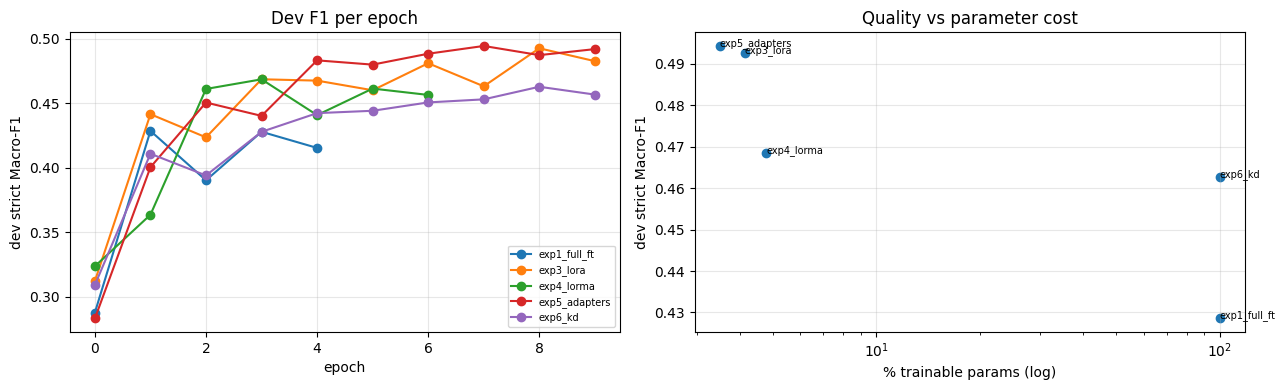

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

R = load_results()
df = pd.DataFrame([dict(experiment=k, **{c: v[c] for c in ["technique", "dev_f1", "dev_p", "dev_r", "dev_f1_viterbi",
                   "dev_f1_argmax", "trainable_params", "total_params", "peak_mem_gb", "train_time_s",
                   "dev_infer_time_s", "best_epoch"]}) for k, v in R.items()])
df["trainable_%"] = (100 * df.trainable_params / df.total_params).round(2)
df["total_M"] = (df.total_params / 1e6).round(1)
df = df.sort_values("dev_f1", ascending=False).reset_index(drop=True)
df.to_csv(os.path.join(PHASE2_DIR, "phase2_encdec_results.csv"), index=False)
display(df[["experiment", "technique", "dev_f1", "dev_p", "dev_r", "dev_f1_viterbi", "dev_f1_argmax",
            "total_M", "trainable_%", "peak_mem_gb", "train_time_s", "dev_infer_time_s"]])

per_label = pd.DataFrame({k: v["per_label_f1"] for k, v in R.items()})
display(per_label.style.background_gradient(axis=None, cmap="Blues").format("{:.3f}"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, v in R.items():
    h = pd.DataFrame(v["history"]); ax[0].plot(h.epoch, h.dev_f1, marker="o", label=k)
ax[0].set(xlabel="epoch", ylabel="dev strict Macro-F1", title="Dev F1 per epoch"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[1].scatter(df["trainable_%"], df.dev_f1)
for _, r in df.iterrows(): ax[1].annotate(r.experiment, (r["trainable_%"], r.dev_f1), fontsize=7)
ax[1].set(xscale="log", xlabel="% trainable params (log)", ylabel="dev strict Macro-F1", title="Quality vs parameter cost")
ax[1].grid(alpha=.3); plt.tight_layout(); plt.savefig(os.path.join(PHASE2_DIR, "phase2_encdec_plots.png"), dpi=150); plt.show()

## 13. Error analysis on the best experiment

In [ ]:
def rebuild(name):
    m = EXPERIMENTS[name]["build"]()
    m.load_state_dict(torch.load(os.path.join(CKPT_DIR, f"{name}.pt"), map_location="cpu"), strict=False)
    return m.to(DEVICE).eval()

BEST = df.iloc[0].experiment
model = rebuild(BEST)
ev = evaluate(model)[DECODE]
cats, conf, examples = error_analysis(ev["pred"], dev_docs)
print(f"Best: {BEST}  dev strict Macro-F1 = {ev['f1']:.4f}\n")
print("Error categories:", dict(cats))
print("\nTop type confusions (gold -> pred):")
for (g, p), c in conf.most_common(10): print(f"  {g:10s} -> {p:10s} {c}")
print("\nRecall by position in document:", recall_by_position(ev["pred"], dev_docs))
for c, exs in examples.items():
    print(f"\n[{c}]")
    for e in exs: print("   ", e)
del model; free()

Best: exp5_adapters  dev strict Macro-F1 = 0.4943

Error categories: {'boundary': 496, 'wrong_type': 226, 'boundary+type': 104, 'spurious': 616, 'missed': 929}

Top type confusions (gold -> pred):
  A.COUNSEL  -> R.COUNSEL  61
  APP        -> PREC       18
  R.COUNSEL  -> A.COUNSEL  17
  PREC       -> COURT      15
  JUDGE      -> PREC       14
  RESP       -> APP        12
  APP        -> AUTH       11
  RESP       -> PREC       8
  WIT        -> APP        7
  AUTH       -> RESP       7

Recall by position in document: {'0%-10%': 0.607, '10%-25%': 0.631, '25%-50%': 0.596, '50%-75%': 0.607, '75%-100%': 0.538}

[boundary]
    ("'India'", 'PREC', ("'India Automobiles'", 'PREC'))
    ("'M.A.A. no 272 of'", 'CASENO', ("'M.A.A. no 272 of 1996'", 'CASENO'))
    ("'fourth quarter'", 'DATE', ("'fourth quarter of 2009-10'", 'DATE'))
    ("'Municipal'", 'AUTH', ("'Municipal Assessment Tribunal'", 'AUTH'))
    ("'March 24, 2012'", 'DATE', ("'March 24, 2012-'", 'DATE'))
    ("'India Automobiles (

## 14. `prediction.json` + `submission.zip` for every experiment
Each experiment is rebuilt from the registry, so the right architecture is always used (this is fix 6). Each zip has `prediction.json` at its root and is validated:
every test ID present, no unknown IDs, integer offsets inside the text, and valid labels.

In [ ]:
def validate_prediction(pred, docs):
    assert set(pred) == set(docs), "test ID mismatch"
    for i, spans in pred.items():
        L = len(docs[i].text)
        for s, e, l in spans:
            assert isinstance(s, int) and isinstance(e, int) and 0 <= s < e <= L, (i, s, e)
            assert l in ENTITY_LABELS, l
    return True

def make_submission(name, method=DECODE):
    model = rebuild(name)
    probs = predict_word_probs(model, test_loader, test_docs)
    pred = {i: [[int(s), int(e), l] for (s, e, l) in decode_doc(test_docs[i], probs[i], method)] for i in test_docs}
    validate_prediction(pred, test_docs)
    out = os.path.join(SUB_DIR, name); os.makedirs(out, exist_ok=True)
    pj = os.path.join(out, "prediction.json")
    with open(pj, "w", encoding="utf-8") as f: json.dump(pred, f, ensure_ascii=False)
    zp = os.path.join(SUB_DIR, f"submission_{name}.zip")
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z: z.write(pj, arcname="prediction.json")
    with zipfile.ZipFile(zp) as z: assert z.namelist() == ["prediction.json"]
    print(f"{name}: {sum(map(len, pred.values())):,} spans over {len(pred)} docs -> {zp}")
    del model; free()
    return zp

for name in load_results():
    make_submission(name)

exp1_full_ft: 4,513 spans over 35 docs -> /content/drive/MyDrive/CS781/Capstone-Project/phase2_lner_mamba/submissions/submission_exp1_full_ft.zip
LoRA on 40 linears
exp3_lora: 4,091 spans over 35 docs -> /content/drive/MyDrive/CS781/Capstone-Project/phase2_lner_mamba/submissions/submission_exp3_lora.zip
LoRMA+ on 40 linears
exp4_lorma: 3,962 spans over 35 docs -> /content/drive/MyDrive/CS781/Capstone-Project/phase2_lner_mamba/submissions/submission_exp4_lorma.zip
exp5_adapters: 3,966 spans over 35 docs -> /content/drive/MyDrive/CS781/Capstone-Project/phase2_lner_mamba/submissions/submission_exp5_adapters.zip
exp6_kd: 3,540 spans over 35 docs -> /content/drive/MyDrive/CS781/Capstone-Project/phase2_lner_mamba/submissions/submission_exp6_kd.zip


### Optional: refit the chosen recipe on fold1 + fold2 for a final submission

In [ ]:
REFIT = None   # e.g. "exp1_full_ft"
if REFIT:
    all_docs = prepare(ALL_LABELED_RAW, "all")
    all_loader = make_loader(all_docs, shuffle=True)
    n_ep = load_results()[REFIT]["best_epoch"] + 1
    cfg = EXPERIMENTS[REFIT]
    EXPERIMENTS[REFIT + "_refit"] = cfg
    seed_everything(); m = cfg["build"]()
    m, _ = train_experiment(REFIT + "_refit", m, cfg["technique"] + " (refit fold1+2)", cfg["lr"],
                            epochs=n_ep, train_loader_=all_loader)
    del m; free()
    make_submission(REFIT + "_refit")

## 15. Checklist and analysis prompts (brief §8.5)
- [ ] ≥ 6 Codabench submissions with *methodologically different* techniques (exp1–6). LoRMA⁺ is in (exp4), and KD is in (exp6).
- [ ] Across Phase 2, all four Phase-1 architectures are covered (this notebook = Mamba).
- [ ] LLM-use declaration updated, and LoRMA [12], LoRA [3], Houlsby [6], BitFit [8], Hinton KD [2] and Mamba (Gu & Dao, 2023) cited.

**Evidence for the report**
1. Technique vs F1 vs % trainable parameters → the summary table and its plot.
2. **Does right context matter for a causal backbone?** Compare `x_linear_head` with `exp1_full_ft` (BiGRU), and `x_bidir` with `exp4_lorma`.
3. Word readout: rerun one recipe with `WORD_READOUT="first"` (the GQLA behaviour) vs `"mean"`.
4. LoRA vs LoRMA⁺ at the same rank and targets (exp3 vs exp4); and Mamba-specific `x_ssm_only` against generic PEFT.
5. Span decoding: `dev_f1_viterbi` vs `dev_f1_argmax`; alignment ceiling from §5.
6. Hard entity types / boundaries → per-label table, `wrong_type` confusions, `boundary` examples; long documents → `recall_by_position`.
7. KD: student params, inference time and peak memory vs the teacher, and the F1 gap.